# Traffic Analytics — Train YOLO26s với dataset mới (v1)

Dataset: **vietnam-vehicle-detection v1** (Roboflow, CC BY 4.0) trong `data/` — 2012 ảnh, train/valid/test = 1509/201/302.

Bốn lớp (đã kiểm tra bằng crop ảnh, `data.yaml` gốc chỉ ghi `'0'..'3'`):

| id | lớp | số box (train) |
|---|---|---|
| 0 | car | 5035 |
| 1 | motorcycle | 6143 |
| 2 | truck | 406 |
| 3 | bus | 125 |

⚠️ Thứ tự khác dataset cũ (cũ: car, motorcycle, **bus, truck**). Code inference/đếm xe dùng model này phải đổi mapping id → tên.

Train trên máy local (GPU RTX 3050 Laptop 4GB) với kernel **Python (traffic-analytics)** (`.venv` của repo, xem `requirements.txt`). Mở notebook từ thư mục gốc repo rồi **Run all**; nếu bị ngắt giữa chừng, chạy lại sẽ tự resume từ `last.pt`.

In [1]:
from pathlib import Path
import os, json

RUN_NAME = 'vehicle_v1_yolo26s'   # đổi tên khi làm thí nghiệm mới
MODEL = 'yolo26s.pt'              # pretrained COCO, Ultralytics tự tải
EPOCHS = 100
PATIENCE = 20
IMGSZ = 640
BATCH = 8                         # GPU 4GB; nếu CUDA out of memory thì giảm 4
WORKERS = 4                       # RAM 16GB: giữ thấp để không tràn RAM
SEED = 42
CLASS_NAMES = ['car', 'motorcycle', 'truck', 'bus']

REPO = Path.cwd()
DATA_DIR = REPO / 'data'
RUNS_DIR = REPO / 'runs'
assert (DATA_DIR / 'data.yaml').is_file(), f'Không thấy data/data.yaml — mở notebook từ thư mục gốc repo (cwd={REPO})'
print('Repo:', REPO)

Repo: g:\code\traffic_anlytic


## Thư viện và GPU

In [2]:
import torch, yaml, ultralytics
from ultralytics import YOLO
print('ultralytics', ultralytics.__version__, '| torch', torch.__version__)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    DEVICE = 0
else:
    raise RuntimeError('Không có CUDA — kiểm tra đã chọn kernel Python (traffic-analytics) chưa.')

ultralytics 8.4.215 | torch 2.11.0+cu128
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## Kiểm tra dữ liệu và tạo data.yaml

`data.yaml` của Roboflow dùng đường dẫn tương đối `../train/images` và tên lớp `'0'..'3'`. Tạo `data/data_train.yaml` với đường dẫn tuyệt đối và tên lớp thật (không sửa file gốc).

In [3]:
from collections import Counter
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
stats = {}
for split in ('train', 'valid', 'test'):
    imgs = [p for p in (DATA_DIR / split / 'images').iterdir() if p.suffix.lower() in IMG_EXT]
    lbl_dir = DATA_DIR / split / 'labels'
    counts, missing, bad, empty = Counter(), 0, 0, 0
    for img in imgs:
        lf = lbl_dir / (img.stem + '.txt')
        if not lf.is_file():
            missing += 1
            continue
        lines = [l.split() for l in lf.read_text().splitlines() if l.strip()]
        if not lines:
            empty += 1
        for p in lines:
            ok = (len(p) == 5 and p[0].isdigit() and int(p[0]) < len(CLASS_NAMES)
                  and all(0 <= float(v) <= 1 for v in p[1:]))
            if not ok:
                bad += 1
                continue
            counts[CLASS_NAMES[int(p[0])]] += 1
    stats[split] = {'images': len(imgs), 'missing_labels': missing, 'empty_labels': empty,
                    'bad_rows': bad, 'boxes': dict(counts)}
    print(f"{split:5s}: {len(imgs):4d} ảnh | thiếu nhãn {missing} | rỗng {empty} | dòng lỗi {bad} | {dict(counts)}")
assert all(s['bad_rows'] == 0 for s in stats.values()), 'Có nhãn lỗi, kiểm tra lại dataset.'

DATA_YAML = DATA_DIR / 'data_train.yaml'
DATA_YAML.write_text(yaml.safe_dump({
    'path': str(DATA_DIR.resolve()),
    'train': 'train/images', 'val': 'valid/images', 'test': 'test/images',
    'nc': len(CLASS_NAMES), 'names': CLASS_NAMES,
}, sort_keys=False))
print(DATA_YAML.read_text())

train: 1509 ảnh | thiếu nhãn 0 | rỗng 0 | dòng lỗi 0 | {'motorcycle': 6143, 'car': 5035, 'truck': 406, 'bus': 125}
valid:  201 ảnh | thiếu nhãn 0 | rỗng 0 | dòng lỗi 0 | {'motorcycle': 827, 'car': 722, 'bus': 16, 'truck': 48}
test :  302 ảnh | thiếu nhãn 0 | rỗng 0 | dòng lỗi 0 | {'car': 975, 'motorcycle': 1263, 'truck': 73, 'bus': 27}
path: G:\code\traffic_anlytic\data
train: train/images
val: valid/images
test: test/images
nc: 4
names:
- car
- motorcycle
- truck
- bus



## Train YOLO26s

Fine-tune từ pretrained `yolo26s.pt`. Nếu đã có `runs/<RUN_NAME>/weights/last.pt` của lượt bị ngắt thì resume; nếu lượt đó đã xong thì bỏ qua.

In [4]:
run_dir = RUNS_DIR / RUN_NAME
last_pt = run_dir / 'weights' / 'last.pt'
best_pt = run_dir / 'weights' / 'best.pt'
status_file = run_dir / 'run_status.json'
done = status_file.is_file() and json.loads(status_file.read_text()).get('status') == 'completed'

if done:
    print('Đã train xong, bỏ qua:', run_dir)
else:
    if last_pt.is_file():
        print('Resume từ', last_pt)
        YOLO(str(last_pt)).train(resume=True)
    else:
        YOLO(MODEL).train(
            data=str(DATA_YAML), epochs=EPOCHS, patience=PATIENCE, imgsz=IMGSZ,
            batch=BATCH, device=DEVICE, workers=WORKERS,
            project=str(RUNS_DIR), name=RUN_NAME, exist_ok=True,
            seed=SEED, deterministic=True, save_period=10, plots=True,
        )
    status_file.write_text(json.dumps({'status': 'completed', 'model': MODEL,
                                       'data': 'vietnam-vehicle-detection v1'}, indent=2))
print('best.pt:', best_pt, best_pt.is_file())

Resume từ g:\code\traffic_anlytic\runs\vehicle_v1_yolo26s\weights\last.pt
Ultralytics 8.4.215  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=g:\code\traffic_anlytic\data\data_train.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.00125, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=g:\co

## Đánh giá

Chọn model theo **validation**; test chỉ dùng để báo cáo kết quả cuối. Metrics lưu vào `runs/<RUN_NAME>/metrics.json`.

In [5]:
model = YOLO(str(best_pt))
summary = {}
for split in ('val', 'test'):
    m = model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                  project=str(run_dir), name=f'eval_{split}', exist_ok=True, plots=True)
    per_class = {}
    for i, c in enumerate(m.box.ap_class_index):
        p, r, ap50, ap = m.box.class_result(i)
        per_class[CLASS_NAMES[int(c)]] = {'precision': round(float(p), 4), 'recall': round(float(r), 4),
                                          'mAP50': round(float(ap50), 4), 'mAP50-95': round(float(ap), 4)}
    summary[split] = {'precision': round(float(m.box.mp), 4), 'recall': round(float(m.box.mr), 4),
                      'mAP50': round(float(m.box.map50), 4), 'mAP50-95': round(float(m.box.map), 4),
                      'per_class': per_class, 'speed_ms': m.speed}
(run_dir / 'metrics.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False))

import pandas as pd
for split, s in summary.items():
    print(f"\n== {split}: P={s['precision']} R={s['recall']} mAP50={s['mAP50']} mAP50-95={s['mAP50-95']}")
    print(pd.DataFrame(s['per_class']).T.to_string())

Ultralytics 8.4.215  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 1776.2±621.7 MB/s, size: 329.3 KB)
val: Scanning G:\code\traffic_anlytic\data\valid\labels.cache... 201 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 201/201  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 1.8it/s 14.5s<0.2s
                   all        201       1613      0.882        0.8      0.888      0.704
                   car        172        722      0.961      0.819      0.954      0.785
            motorcycle        197        827      0.897       0.84      0.938      0.657
                 truck         35         48      0.909      0.854      0.936      0.766
                   bus         15         16      0.762      0.688      0.724      0.609
Speed: 0.6m

## Xem thử dự đoán trên ảnh test

Results saved to G:\code\traffic_anlytic\runs\vehicle_v1_yolo26s\samples


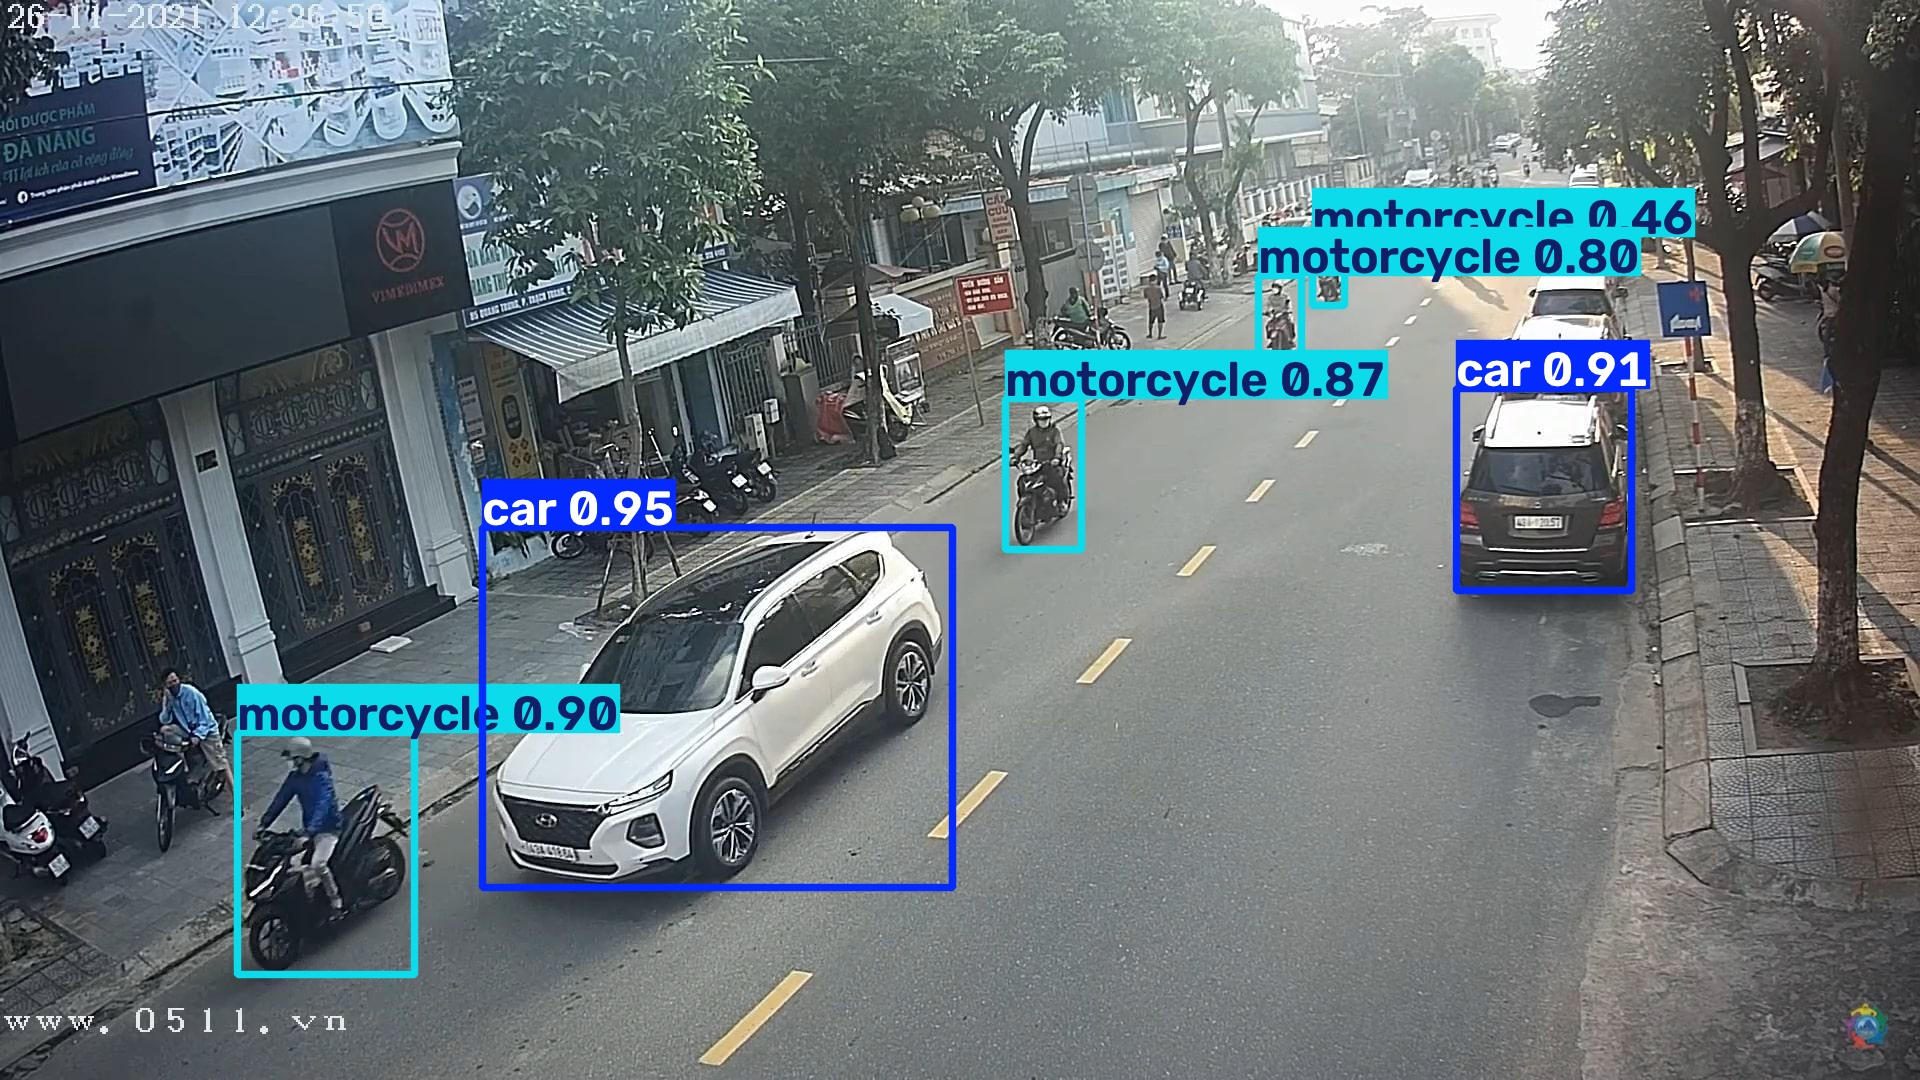

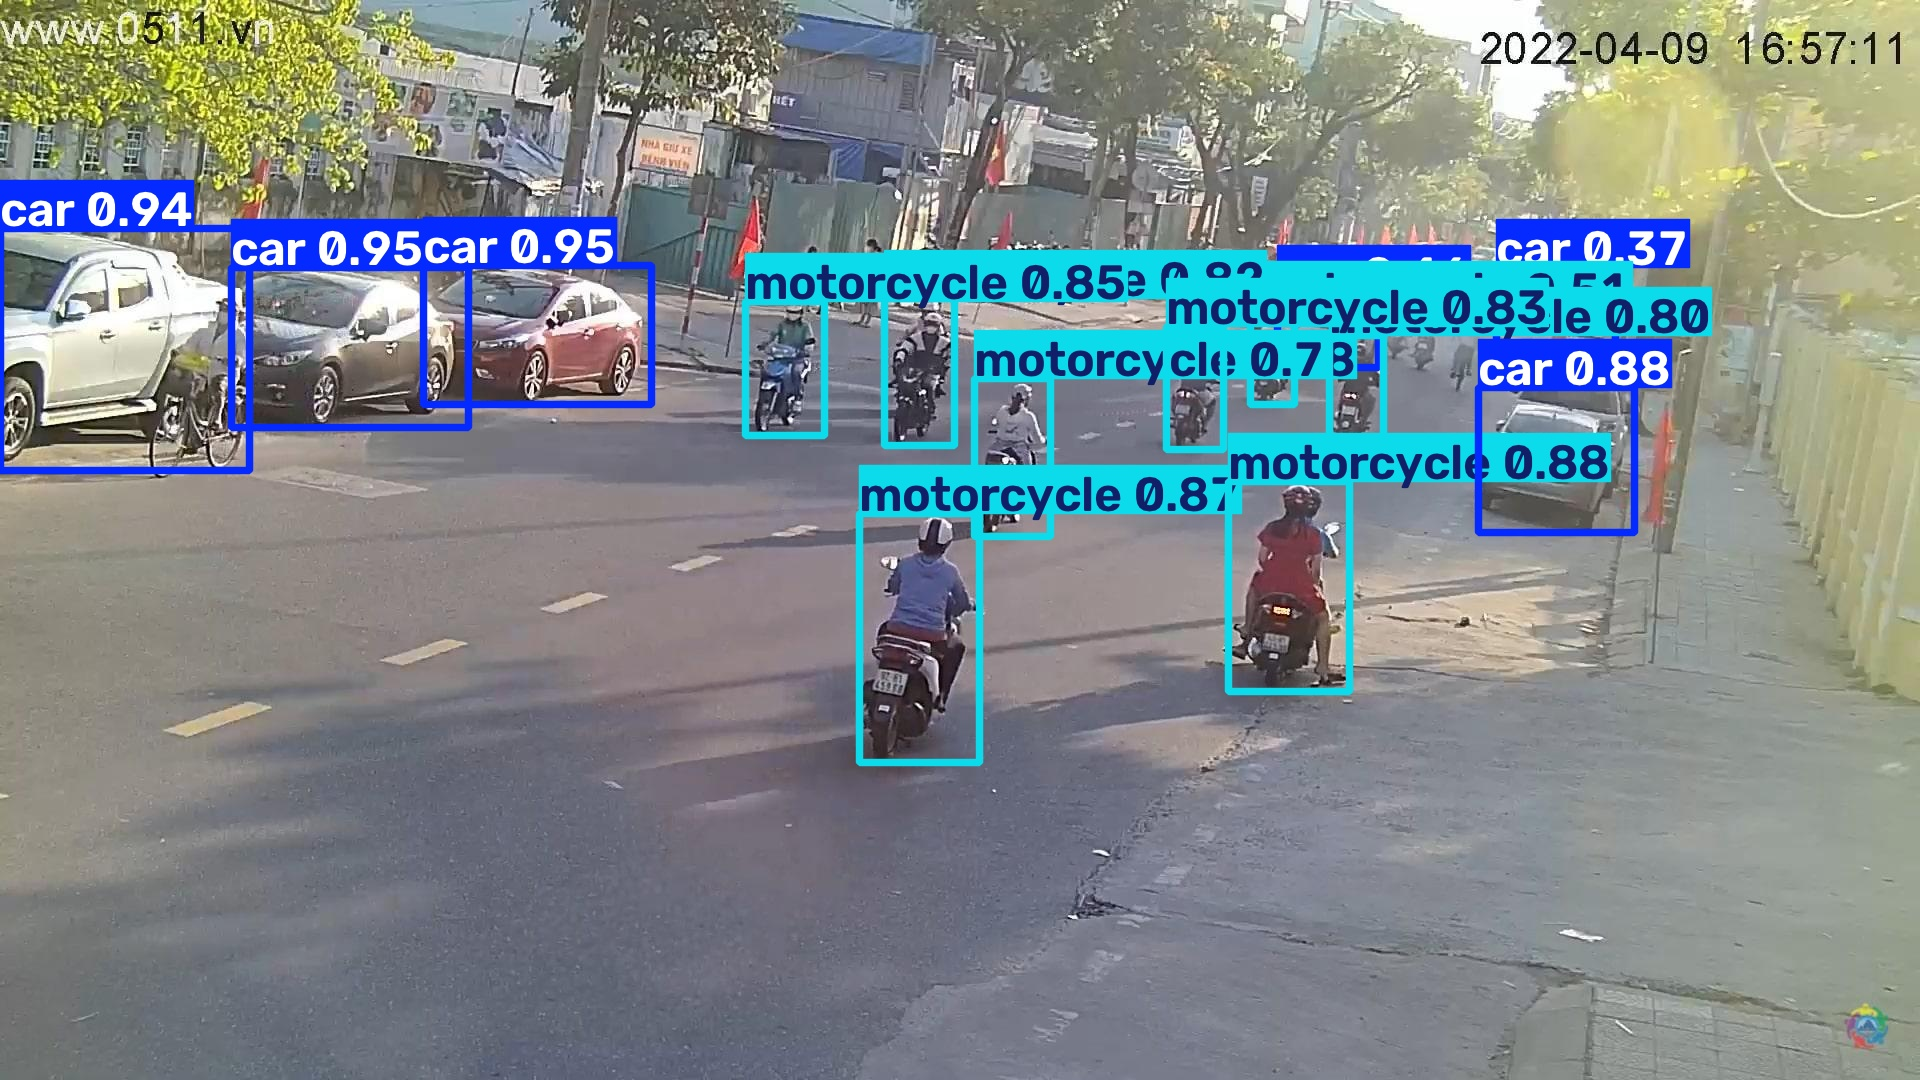

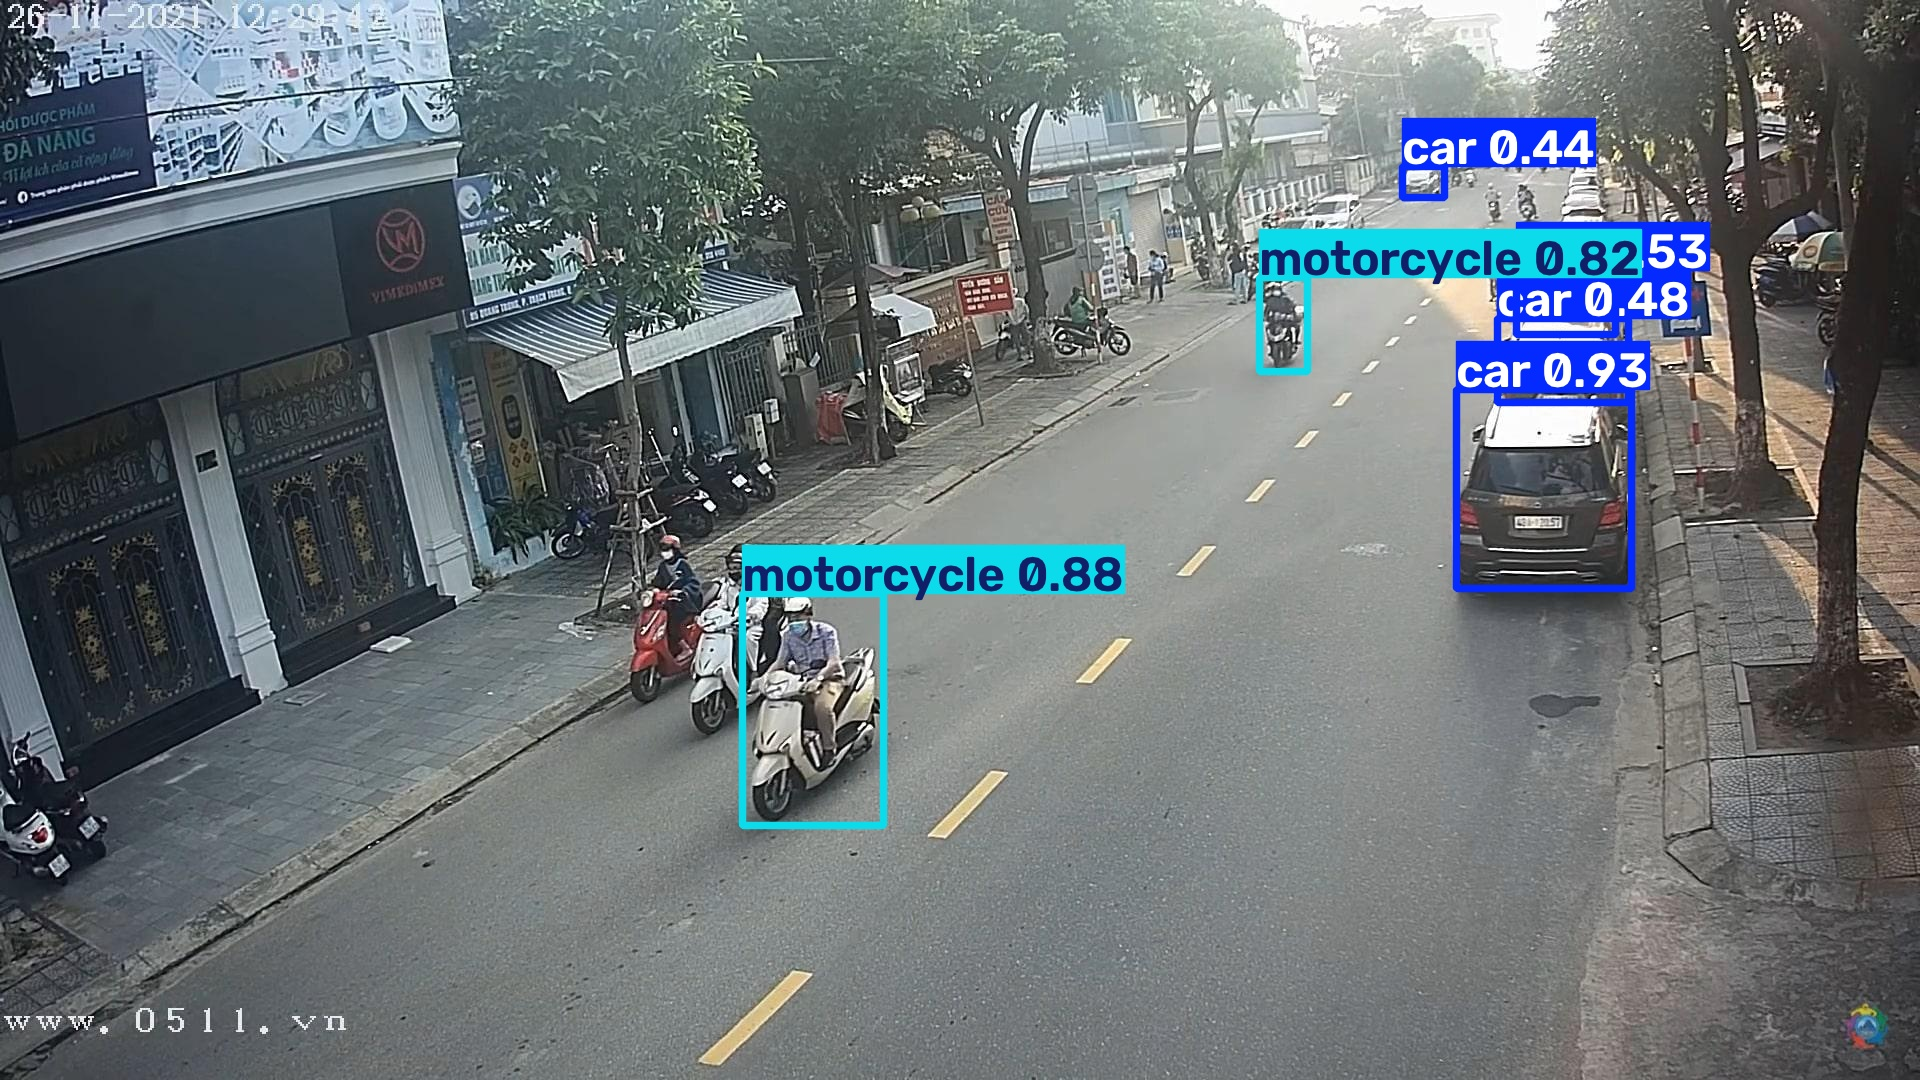

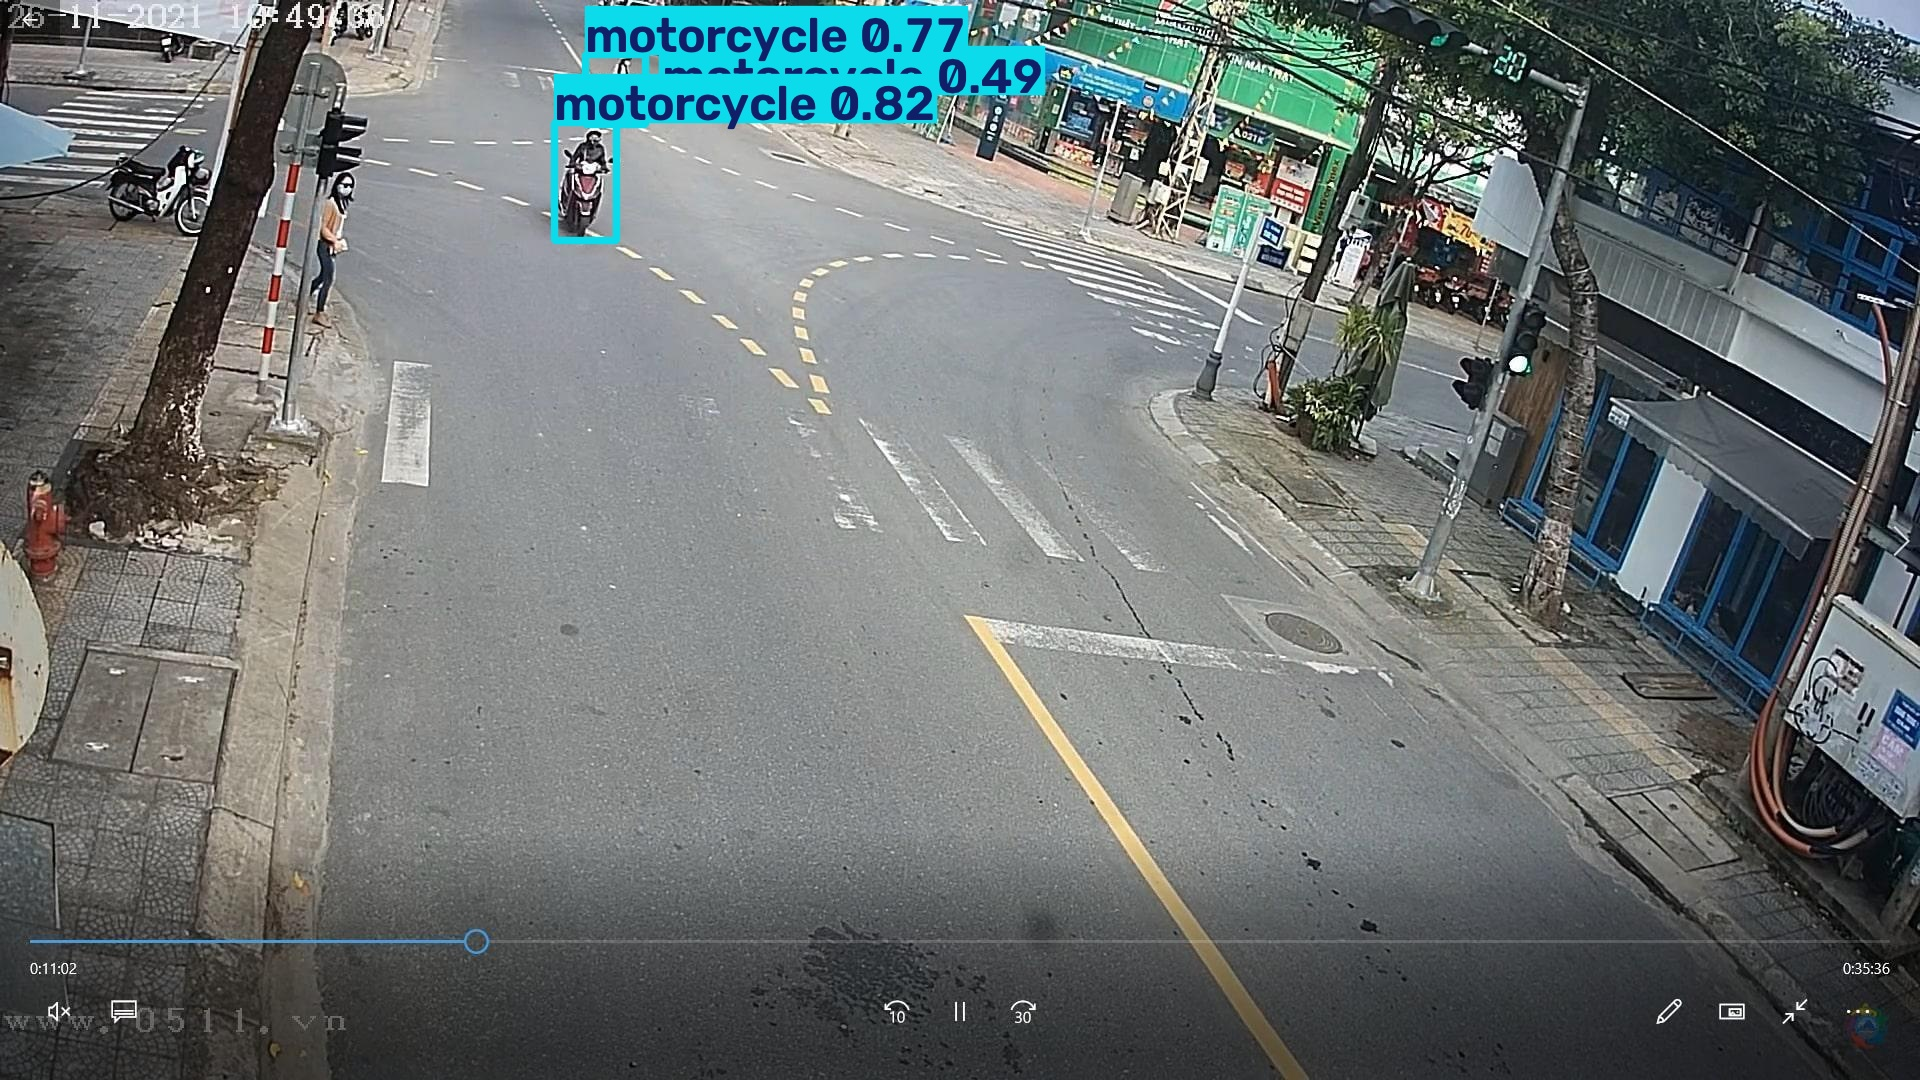

In [6]:
import random
from IPython.display import Image as IPImage, display
test_imgs = sorted((DATA_DIR / 'test' / 'images').iterdir())
random.Random(SEED).shuffle(test_imgs)
preds = model.predict([str(p) for p in test_imgs[:4]], imgsz=IMGSZ, conf=0.25, device=DEVICE,
                      project=str(run_dir), name='samples', exist_ok=True, save=True, verbose=False)
for r in preds:
    display(IPImage(filename=str(Path(r.save_dir) / Path(r.path).name), width=640))